Actual Values: [2 0 2 2 0 0 1 0 2 0]
Predicted Values: [2 1 2 2 0 0 0 0 2 0]

Accuracy: 0.86

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.94      0.91        32
           1       0.91      0.76      0.83        41
           2       0.78      0.93      0.85        27

    accuracy                           0.86       100
   macro avg       0.86      0.87      0.86       100
weighted avg       0.87      0.86      0.86       100



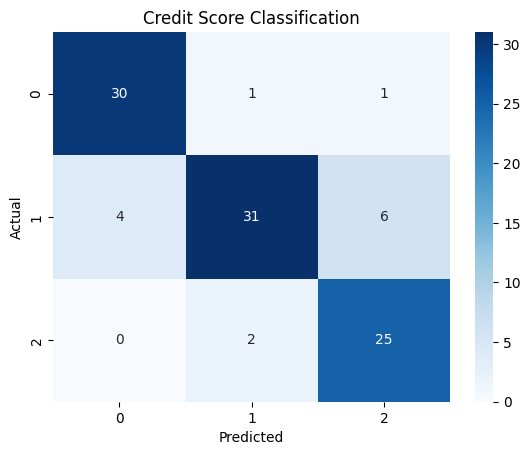


New Customer Credit Category: Standard


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns

# Generate sample credit dataset
X, y = make_classification(
    n_samples=500,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_classes=3,
    n_clusters_per_class=1,
    random_state=42
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
model = RandomForestClassifier(random_state=42)

# Train model
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

# Display results
print("Actual Values:", y_test[:10])
print("Predicted Values:", y_pred[:10])

print("\nAccuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, cmap='Blues', fmt='d')
plt.title("Credit Score Classification")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Predict new customer
new_customer = np.array([[0.5, -0.5, 1.0, 0.2]])

prediction = model.predict(new_customer)

categories = ['Poor', 'Standard', 'Good']

print("\nNew Customer Credit Category:",
      categories[prediction[0]])